In [1]:
from sasview_fit2d import fit_2d_data, calculate_nematic_order_from_fit

## I. Gaussian distribution

**Define args**

In [ ]:
filename="./E-field-isotropic/280V_240.dat"

# Sasview model
model = 'elliptical_cylinder'  
params = {
    "phi": 90, "theta": 90, "psi": 0,

    "theta_pd_type": 'gaussian', #polydispersity function
    "theta_pd": 15, #polydispersity
    "theta_pd_n": 100, #number of steps in polydispersity
    "theta_pd_nsigma": 3, #range of polydispersity

#    "phi_pd_type": 'uniform', #polydispersity function
#    "phi_pd": 90, #polydispersity
#    "phi_pd_n": 100, #number of steps in polydispersity

    "phi_pd_type": 'gaussian', #polydispersity function
    "phi_pd": 15, #polydispersity
    "phi_pd_n": 100, #number of steps in polydispersity
    "phi_pd_nsigma": 3, #range of polydispersity

#   "psi_pd_type": 'uniform', #polydispersity function
#    "psi_pd": 90, #polydispersity
#    "psi_pd_n": 20, #number of steps in polydispersity


    "axis_ratio": 1, # ratio for the elliptic crosssection, here for a cylinder 

    "radius_minor": 141, #radius of the NRs
    "radius_minor_pd_type": 'gaussian', #number of steps in polydispersity
    "radius_minor_pd": 0.06, #polydispersity
    "radius_minor_pd_n": 8, #number of steps in polydispersity
    "radius_minor_pd_nsigma": 4, #range of polydispersity

    "length":10000,

    "background": 1,
    "scale": 0.02
}

# ROI
roi_params = {'qmax_x':0.08, "qmax_y":0.03, 'q_center':0.01}

# parameters fitting_range (optional)
fit_ranges = {
    'scale': (0.005, 0.1),
    'background': (0.01, 10),
    'theta_pd': (12, 16),
    'phi_pd': (12, 16)
}

**Run the fit**

Loading data from ./E-field-isotropic/280V_240.dat...
Applying ROI masks...
Number of points after filtering: 78184
Number of points after slicing (/20): 3910
Loading model: elliptical_cylinder
Applying fitting ranges...
  scale: [0.005, 0.1]
  background: [0.01, 10]
  theta_pd: [12, 16]
  phi_pd: [12, 16]


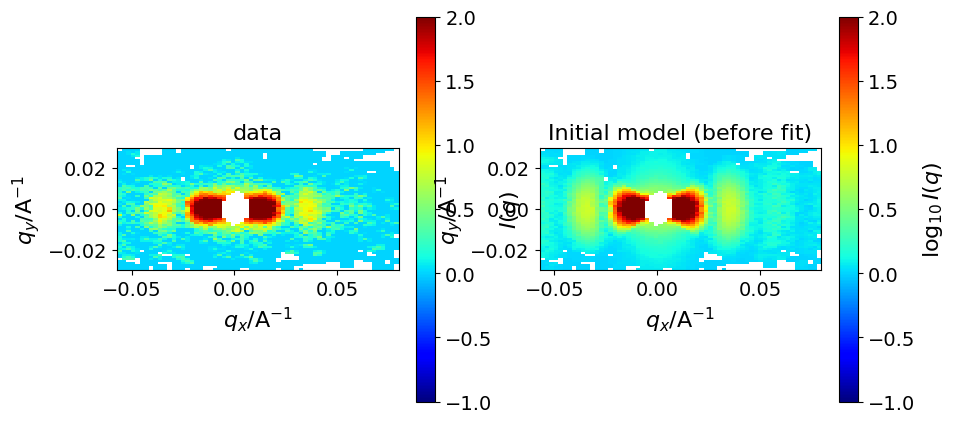


Starting fit (method: lm, steps: 20)...
step 1 cost 441.9425(12)
                              background |.........          1 in (0.01,10)
                                  phi_pd .......|..         15 in (12,16)
                                   scale .|........       0.02 in (0.005,0.1)
                                theta_pd .......|..         15 in (12,16)
step 2 cost 381.7705(12)
step 3 cost 354.0896(12)
step 4 cost 308.6460(12)
                              background |.........   0.928644 in (0.01,10)
                                  phi_pd .......|..    14.9227 in (12,16)
                                   scale .|........  0.0173431 in (0.005,0.1)
                                theta_pd |.........         12 in (12,16)
step 5 cost 238.3703(12)
step 6 cost 171.6653(12)
step 7 cost 166.7214(12)
                              background |.........   0.848312 in (0.01,10)
                                  phi_pd ......|...    14.4268 in (12,16)
                              

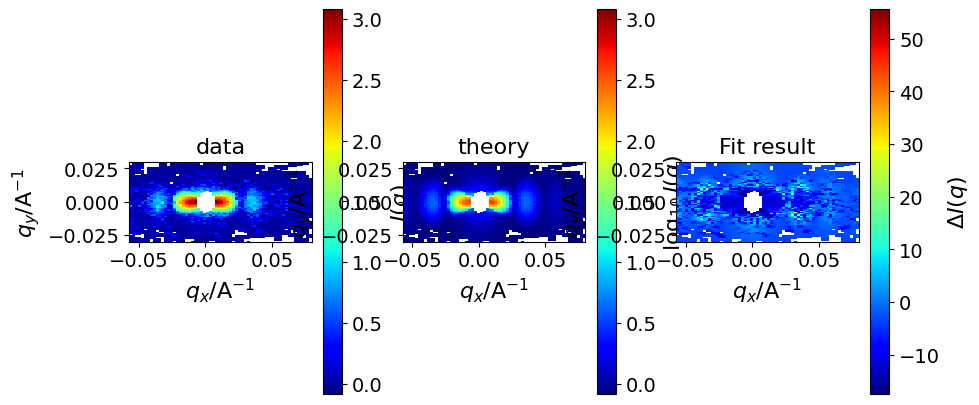


=== Fit summary ===
                              background |.........   0.813933 in (0.01,10)
                                  phi_pd .|........    12.7565 in (12,16)
                                   scale |.........  0.0110973 in (0.005,0.1)
                                theta_pd .........|         16 in (12,16)

Chi² = 79.4386


In [3]:
result = fit_2d_data(
    filename=filename,
    model_name=model,
    params=params,
    roi_params=roi_params,
    fit_ranges=fit_ranges,
    slicing=20,
    error_coeff=0.05,
    I_min=0.0001,
    fit_method='lm',
    fit_steps=20,
    ftol=1.5e-08,
    xtol=1.5e-08,
    verbose=True,
    plot_results=True
)

**Display fitted parameters**

In [4]:
from sasview_fit2d import print_fitted_parameters

print_fitted_parameters(result)


=== Fitted parameters ===
background           =     0.8139 ±     0.0015
phi_pd               =    12.7565 ±     0.0061
scale                =     0.0111 ±     0.0000
theta_pd             =    16.0000 ±     0.9601


**Calculate nematic order parameter**

**Access individual S values**

In [7]:
from sasview_fit2d import calculate_nematic_order_from_fit

# Option 1: Auto-detect distribution type from model (recommandé)
nematic_theta = calculate_nematic_order_from_fit(result, angle_param='theta')
S_theta = nematic_theta['S']

# Option 2: Specify distribution type explicitly
nematic_phi = calculate_nematic_order_from_fit(result, angle_param='phi', distribution_type='gaussian')
S_phi = nematic_phi['S']

# Option 3: For Maier-Saupe (if you were using it)
# nematic_theta = calculate_nematic_order_from_fit(result, angle_param='theta', distribution_type='maier_saupe')

print(f"\nS_theta = {S_theta:.5f}  (distribution: {nematic_theta['distribution_type']})")
print(f"S_phi   = {S_phi:.5f}  (distribution: {nematic_phi['distribution_type']})")


S_theta = 0.79384  (distribution: gaussian)
S_phi   = 0.86289  (distribution: gaussian)


## II. Maier Saupe distribution

In [2]:
filename="./E-field-isotropic/280V_240.dat"

# Sasview model
model = 'elliptical_cylinder'  # Nom corrigé (avec underscore)

params = {
    "phi": 90, "theta": 90, "psi": 0,

    "theta_pd_type": 'maier_saupe', #polydispersity function
    "theta_pd": 10, #polydispersity
    "theta_pd_n": 40, #number of steps in polydispersity
    "theta_pd_nsigma": 3, #range of polydispersity

#    "phi_pd_type": 'uniform', #polydispersity function
#    "phi_pd": 90, #polydispersity
#    "phi_pd_n": 100, #number of steps in polydispersity

    "phi_pd_type": 'maier_saupe', #polydispersity function
    "phi_pd": 10, #polydispersity
    "phi_pd_n": 40, #number of steps in polydispersity
    "phi_pd_nsigma": 3, #range of polydispersity

#   "psi_pd_type": 'uniform', #polydispersity function
#    "psi_pd": 90, #polydispersity
#    "psi_pd_n": 20, #number of steps in polydispersity


    "axis_ratio": 1, # ratio for the elliptic crosssection, here for a cylinder 

    "radius_minor": 141, #radius of the NRs
    "radius_minor_pd_type": 'gaussian', #number of steps in polydispersity
    "radius_minor_pd": 0.06, #polydispersity
    "radius_minor_pd_n": 8, #number of steps in polydispersity
    "radius_minor_pd_nsigma": 4, #range of polydispersity

    "length":10000,

    "background": 1,
    "scale": 0.05
}
# ROI
roi_params = {'qmax_x':0.08, "qmax_y":0.03, 'q_center':0.01}

# parameters fitting_range (optional)
fit_ranges = {
    'scale': (0.005, 0.1),
    'background': (0.01, 10),
    'theta_pd': (12, 16),
    'phi_pd': (12, 16)
}

In [3]:
result = fit_2d_data(
    filename=filename,
    model_name=model,
    params=params,
    roi_params=roi_params,
    fit_ranges=fit_ranges,
    slicing=20,
    error_coeff=0.05,
    I_min=0.0001,
    fit_method='lm',
    fit_steps=20,
    ftol=1.5e-08,
    xtol=1.5e-08,
    verbose=True,
    plot_results=True
)

Loading data from ./E-field-isotropic/280V_240.dat...
Applying ROI masks...
Number of points after filtering: 78184
Number of points after slicing (/20): 3910
Loading model: elliptical_cylinder
Applying fitting ranges...
  scale: [0.005, 0.1]
  background: [0.01, 10]
  theta_pd: [12, 16]
  phi_pd: [12, 16]


KeyError: 'maier_saupe'

<Figure size 1000x500 with 0 Axes>

In [ ]:
from sasview_fit2d import calculate_nematic_order_from_fit

# Option 1: Auto-detect distribution type from model (recommandé)
nematic_theta = calculate_nematic_order_from_fit(result, angle_param='theta')
S_theta = nematic_theta['S']

# Option 2: Specify distribution type explicitly
nematic_phi = calculate_nematic_order_from_fit(result, angle_param='phi')
S_phi = nematic_phi['S']